# ThAr IP

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import matplotlib.pyplot as plt
from gaoesrvip import select_lines, fit

## Data

In [2]:
thar = "../data/ThAr20251107_2.center.fits"
wavelength_file = "../data/ecThAr20251107_2.center"
orders = [104]

In [3]:
data = select_lines(
    thar, wavelength_file, orders=orders, gain=1.935, read_noise=4.0,
    order_offset=100, half_window=7, saturation=51000,
    blend_guard=2.0, resolving_power=65000,
    max_center_shift=1.0, max_width_error=0.10,
)

## Individual

In [4]:
individual = fit(data, mode="individual", tophat=True)

Order 104: 28 lines, individual, MCMC, tophat=True


sample: 100%|██████████| 1000/1000 [00:29<00:00, 34.00it/s, 255 steps of size 2.59e-02. acc. prob=0.96]


                        mean       std    median      5.0%     95.0%     n_eff     r_hat
 local_scaled[0,0]      0.40      0.00      0.41      0.40      0.41     61.84      1.00
 local_scaled[0,1]      0.50      0.00      0.50      0.50      0.50    337.01      1.00
 local_scaled[0,2]      0.13      0.02      0.12      0.10      0.15     74.38      1.00
 local_scaled[0,3]      0.58      0.07      0.58      0.40      0.65    123.55      1.00
 local_scaled[1,0]      0.41      0.00      0.41      0.41      0.41    469.09      1.00
 local_scaled[1,1]      0.50      0.00      0.50      0.50      0.50    533.68      1.00
 local_scaled[1,2]      0.12      0.00      0.12      0.12      0.13    612.45      1.00
 local_scaled[1,3]      0.37      0.03      0.37      0.33      0.41    273.22      1.00
 local_scaled[2,0]      0.41      0.00      0.41      0.40      0.41    705.85      1.00
 local_scaled[2,1]      0.50      0.00      0.50      0.50      0.50    733.05      1.00
 local_scaled[2,2]  

In [5]:
individual.parameters

,order,line_id,parameter,p16,median,p84
0,104,0,sigma1_kms,1.381880,1.533050,1.617928
1,104,0,fraction,0.031208,0.134356,0.328340
2,104,0,sigma2_kms,1.062676,4.023409,6.349009
3,104,0,delta_kms,-3.011479,-0.102170,2.291460
4,104,0,centroid_kms,-0.399936,-0.004203,0.454005
...,...,...,...,...,...,...
191,104,27,sigma2_kms,1.804675,3.194913,5.872850
192,104,27,delta_kms,-2.060169,0.166287,2.848069
193,104,27,centroid_kms,-0.287363,0.014733,0.319299
194,104,27,intrinsic_fwhm_kms,5.486476,5.748170,5.996086


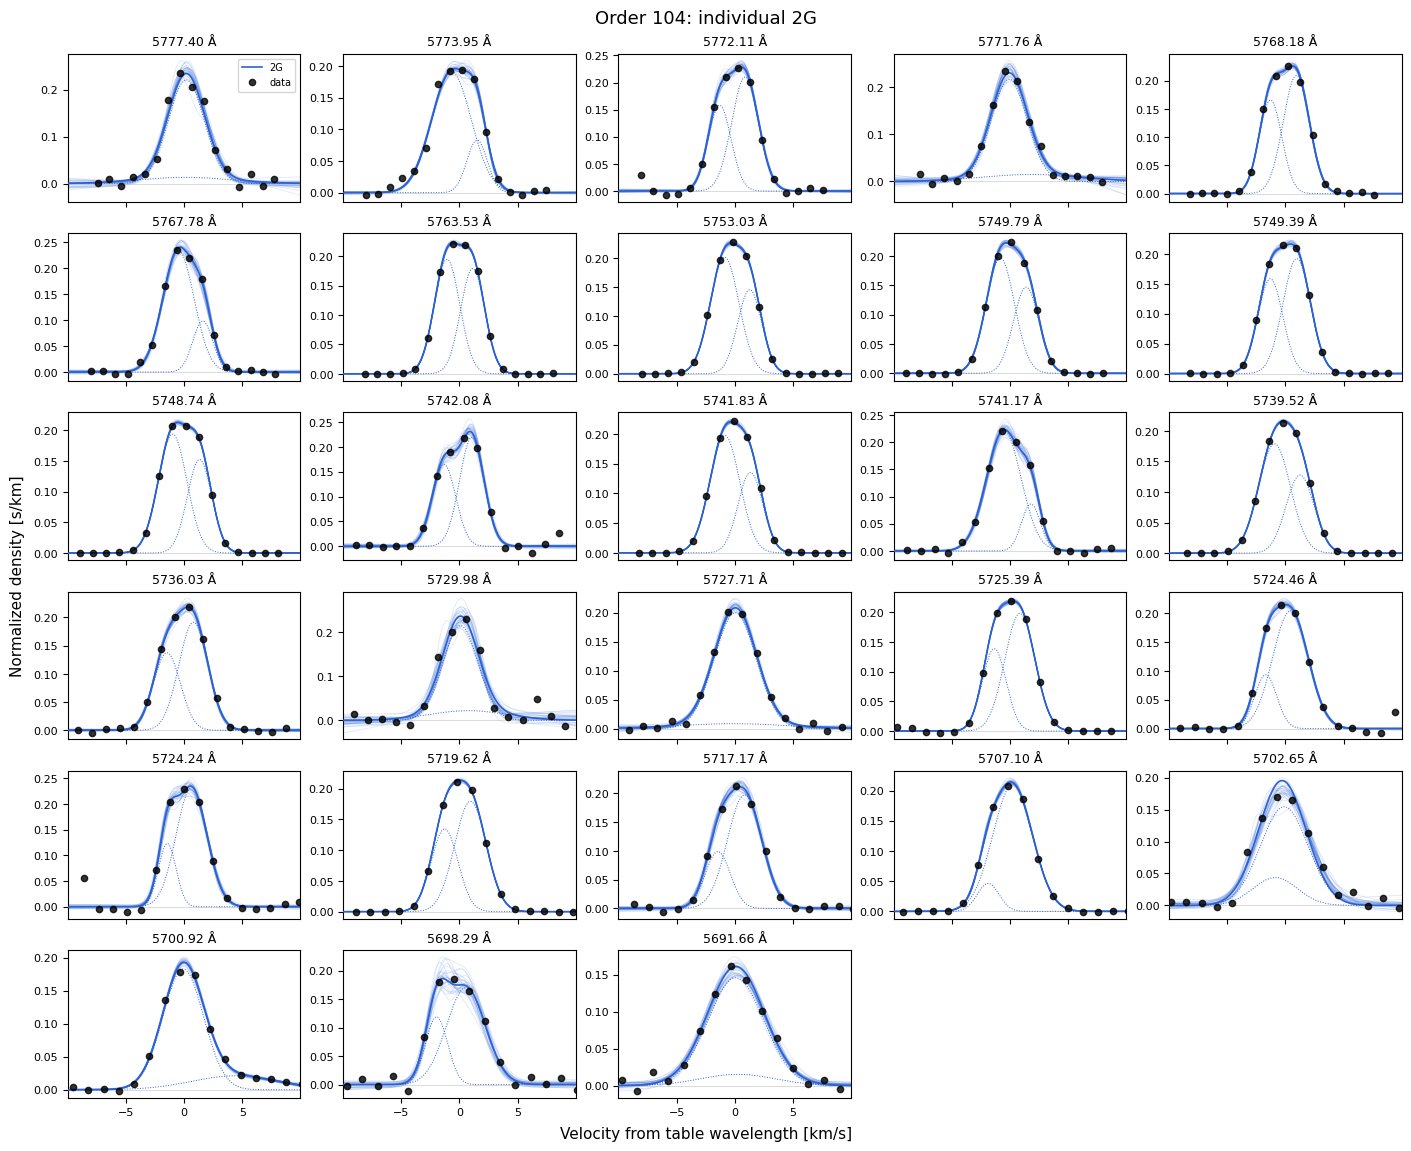

In [6]:
individual.plot_lines()
plt.show()

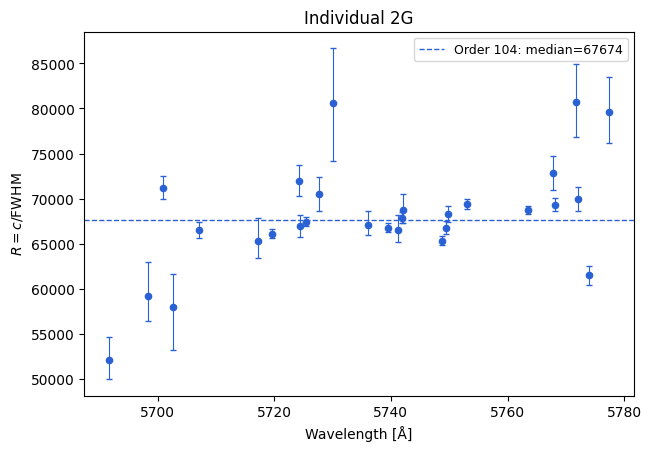

In [7]:
individual.resolving_power();

## Common

In [8]:
common = fit(data, mode="common", tophat=True)

Order 104: 28 lines, common, MCMC, tophat=True


sample: 100%|██████████| 1000/1000 [00:12<00:00, 80.20it/s, 31 steps of size 9.08e-02. acc. prob=0.88] 


                        mean       std    median      5.0%     95.0%     n_eff     r_hat
 local_scaled[0,0]      0.41      0.00      0.41      0.40      0.41    679.77      1.00
 local_scaled[0,1]      0.50      0.00      0.50      0.50      0.50    643.21      1.00
 local_scaled[0,2]      0.12      0.00      0.12      0.11      0.13    544.56      1.00
 local_scaled[0,3]      0.33      0.02      0.33      0.31      0.36    447.43      1.00
 local_scaled[1,0]      0.41      0.00      0.41      0.41      0.41    393.62      1.01
 local_scaled[1,1]      0.50      0.00      0.50      0.50      0.50    710.86      1.00
 local_scaled[1,2]      0.12      0.00      0.12      0.12      0.12    695.06      1.00
 local_scaled[1,3]      0.23      0.01      0.23      0.22      0.24    225.54      1.00
 local_scaled[2,0]      0.41      0.00      0.41      0.41      0.41    405.50      1.00
 local_scaled[2,1]      0.50      0.00      0.50      0.50      0.50    575.37      1.00
 local_scaled[2,2]  

In [9]:
common.parameters

,order,parameter,p16,median,p84
0,104,sigma1_kms,1.124321,1.130593,1.138901
1,104,fraction,0.470249,0.480708,0.487197
2,104,sigma2_kms,1.097481,1.105923,1.112580
3,104,delta_kms,2.222169,2.229388,2.235818
4,104,centroid_kms,1.048387,1.071688,1.086032
5,104,intrinsic_fwhm_kms,4.475894,4.488528,4.498499
6,104,R,66642.770417,66790.823536,66979.345688


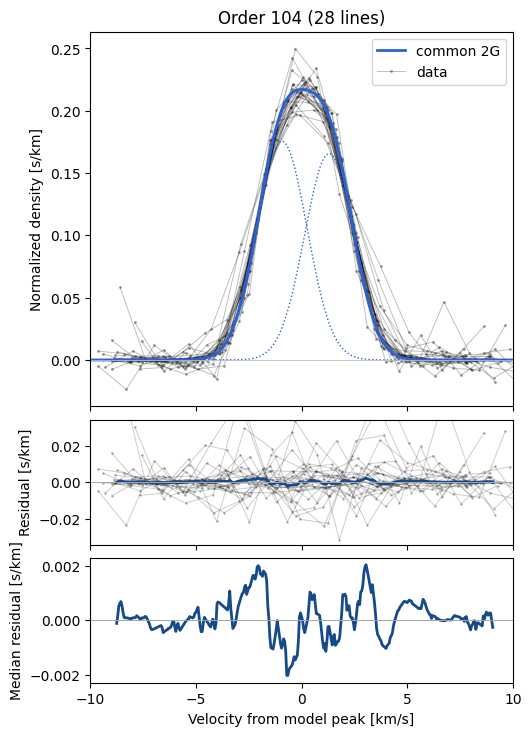

In [10]:
common.overlay();